# Target associations and leakage audit

Test the hypothesis of a cheap target shortcut with fixed, prompt-group-separated
training/development/confirmation partitions. Predictors and all target statistics
are fitted using training rows only. Confirmation was previously inspected, so this
is exploratory replication. The audit uses no GPU, external API or new submission.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
repo=Path.cwd()
if repo.name=='notebooks':repo=repo.parent
r=json.loads((repo/'results/attempt_005_target_audit/results.json').read_text())
table=pd.DataFrame([{'model':m['model'],'dev_loss':m['metrics']['dev']['log_loss'],
 'confirmation_loss':m['metrics']['confirmation']['log_loss'],
 'confirmation_accuracy':m['metrics']['confirmation']['accuracy']} for m in r['models']])
display(table)
print(r['protocol'])


,model,dev_loss,confirmation_loss,confirmation_accuracy
0,training_prior,1.097216,1.097234,0.349112
1,id_and_position_only,1.100541,1.103024,0.332057
2,length_only,1.048934,1.049379,0.452315
3,input_structure,1.036996,1.030591,0.470588
4,model_identity_only,1.042011,1.041853,0.451444
5,model_pair_frequency,1.054894,1.053280,0.435781
6,identity_plus_structure,1.003389,0.991958,0.508006
7,structure_shuffled_training_targets,1.103023,1.100296,0.352767


{'train_partition_only_for_fitting': True, 'prompt_overlap_between_partitions': False, 'categorical_smoothing_pseudocount': 30, 'numeric_factor_bins': 'Train-only decile edges', 'gbdt': '250 trees, 15 leaves, min child 150, learning rate 0.05, lambda 5, no validation tuning', 'confirmation': 'Previously inspected confirmation; exploratory replication, not an untouched evaluation', 'test_unavailable_fields': ['model_a', 'model_b'], 'public_visible_test_rows': 3, 'scope': 'No new model training on GPU, external APIs or competition submission'}


`model_identity_only`, `model_pair_frequency` and `identity_plus_structure`
are unavailable-input diagnostics: the test file has no model names. They cannot
be used directly for submission. The shape model uses only explicitly recorded
text descriptors, excluding ID, split, class, canonical class and model identity.


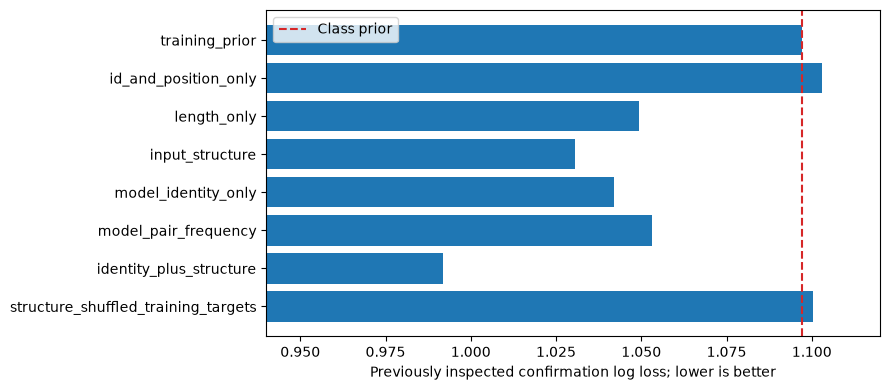

In [2]:
fig,ax=plt.subplots(figsize=(9,4))
ax.barh(table.model,table.confirmation_loss)
ax.axvline(table.loc[table.model=='training_prior','confirmation_loss'].iloc[0],color='tab:red',linestyle='--',label='Class prior')
ax.set(xlim=(.94,1.12),xlabel='Previously inspected confirmation log loss; lower is better')
ax.invert_yaxis();ax.legend();fig.tight_layout()
figures=Path.home()/'database/llm_classification_finetuning/runs/attempt_005_target_audit/figures'
figures.mkdir(exist_ok=True)
fig.savefig(figures/'diagnostic_models.png',dpi=160);plt.show()


In [3]:
factors=pd.DataFrame([{'factor':x['factor'],'categories':x['categories'],
 'training_MI_nats':x['mutual_information_nats_training'],'Cramer_V_all_rows':x['cramers_v_all_rows'],
 'dev_loss':x['metrics']['dev']['log_loss'],
 'confirmation_loss':x['metrics']['confirmation']['log_loss']} for x in r['univariate_factors']])
display(factors.head(20))
display(pd.DataFrame(r['conditional_associations']))
display(pd.DataFrame(r['strong_model_pairs']))


,factor,categories,training_MI_nats,Cramer_V_all_rows,dev_loss,confirmation_loss
0,response_word_difference,10,0.034141,0.190926,1.059039,1.060046
1,ordered_model_pair,2409,0.117626,0.315258,1.062159,1.060086
2,log_answer_word_ratio,10,0.026388,0.165762,1.068935,1.068956
3,model_a,64,0.024441,0.155482,1.074283,1.073944
4,model_b,64,0.023414,0.151576,1.074906,1.075710
5,longer_side,2,0.018807,0.193317,1.078169,1.078178
6,list_difference,6,0.012412,0.114855,1.085251,1.081324
7,response_a_chars,10,0.007684,0.092688,1.085647,1.085425
8,response_a_words,10,0.007419,0.090881,1.086834,1.085562
9,response_a_tokens,10,0.007725,0.092075,1.087423,1.084798


,factor,value,rows,winner_model_a,winner_model_b,winner_tie
0,answer_equal_exact,False,57202,0.350547,0.343292,0.306161
1,answer_equal_exact,True,275,0.043636,0.054545,0.901818
2,answer_equal_whitespace,False,57195,0.350590,0.343334,0.306076
3,answer_equal_whitespace,True,282,0.042553,0.053191,0.904255
4,both_answers_empty,False,57458,0.349142,0.341954,0.308904
5,both_answers_empty,True,19,0.157895,0.210526,0.631579
6,one_answer_empty,False,57452,0.349022,0.341903,0.309075
7,one_answer_empty,True,25,0.480000,0.360000,0.160000
8,both_refusals,False,55810,0.351765,0.344616,0.303619
9,both_refusals,True,1667,0.259148,0.251350,0.489502


,pair,train_rows,largest_class_fraction,class_counts
0,gpt-3.5-turbo-1106 | gpt-4-1106-preview,464,0.637931,"[47, 296, 121]"
1,gpt-4-1106-preview | openchat-3.5,100,0.610000,"[61, 20, 19]"
2,gpt-3.5-turbo-0613 | gpt-4-1106-preview,585,0.606838,"[80, 355, 150]"
3,alpaca-13b | vicuna-13b,107,0.588785,"[19, 63, 25]"
4,oasst-pythia-12b | vicuna-13b,132,0.583333,"[19, 77, 36]"
5,claude-instant-1 | vicuna-7b,128,0.578125,"[74, 20, 34]"
6,gpt-3.5-turbo-0613 | palm-2,108,0.574074,"[62, 22, 24]"
7,claude-2.1 | gpt-4-0125-preview,100,0.570000,"[19, 57, 24]"
8,claude-2.1 | gpt-4-1106-preview,869,0.565017,"[165, 491, 213]"
9,gpt-4-1106-preview | mixtral-8x7b-instruct-v0.1,293,0.539249,"[158, 44, 91]"


The best broadly useful single factor is **response word-count difference**.
Its lookup gives 1.05904 development / 1.06005 confirmation loss. Identity pairs
also have signal; cardinality makes in-sample mutual information optimistic, so
out-of-partition loss is the primary comparison.

Identical answers imply a tie in **248/275 cases (90.18%)**, but cover only 0.48%
of the dataset. The 27 non-tie votes in that subgroup suggest imperfect labeling;
they cannot establish the global irreducible error rate.


In [4]:
display(pd.DataFrame(r['structure_feature_importance']).head(15))
display(pd.DataFrame(r['duplicate_audit']).T)
display(r['target_derived_positive_control'])
assert all(x['cross_partition_groups']==0 for x in r['duplicate_audit'].values())
assert r['target_derived_positive_control']['reconstructed_accuracy']==1
for m in r['models']:
 assert not set(m['features']) & {'label','canonical_label','winner_model_a','winner_model_b','winner_tie'}
print('All diagnostic feature lists exclude target-derived fields.')


,feature,gain
0,response_word_difference,27609.561315
1,answer_word_jaccard,13263.772846
2,answer_length_ratio,4475.991843
3,prompt_tokens,4471.513289
4,response_a_chars,3154.994469
5,response_a_refusal,3122.723539
6,prompt_chars,2994.917304
7,response_b_chars,2977.583618
8,response_b_tokens,2973.135472
9,total_content_tokens,2918.100264


,duplicate_groups,rows_in_duplicate_groups,cross_partition_groups
prompt_group,3286,9550,0
comparison_hash,29,100,0
canonical_comparison_hash,39,123,0


{'field': 'canonical_label',
 'purpose': 'Canonicalized human vote for duplicate-consistency EDA',
 'reconstruction': 'Swap A/B in canonical_label when parsed response_a > parsed response_b lexicographically',
 'reconstructed_accuracy': 1.0,
 'deployed_input': False,
 'warning': 'This is actual target-derived metadata. Feeding it to a model would leak the answer; it is excluded from every predictive experiment above.'}

All diagnostic feature lists exclude target-derived fields.


**An actual leaking helper exists in our EDA cache:** `canonical_label` is the
human label remapped after lexicographically sorting the answer texts. It permits
perfect target reconstruction when combined with the ordering bit. This deliberate
positive control is excluded from all predictors; source inspection places its
original use in duplicate-label consistency analysis, not model inputs.

No duplicate comparison crosses the grouped partitions. ID/order features are at
chance, and shuffled training targets remove the descriptor signal. These checks
find no explanation for 0.8 from cheap metadata. They neither prove a 1.0 honest
loss floor nor rule out every possible source of contamination in pretrained models.

See `TARGET_AUDIT.md` for findings and input-source audit. Full predictions and
standalone figures remain under `~/database/llm_classification_finetuning/runs/attempt_005_target_audit`.
